# Cross-Class Feature Exploration: Soccer vs. Baseball vs. Basketball
**Author:** Chris Yang

This notebook provides two comprehensive perspectives to compare all 12 survey features across the three target classes:
1. **Part 1: Independent 1x3 Horizontal Side-by-Side Subplots** (`[Soccer] | [Baseball] | [Basketball]`) to evaluate each sport's internal distributions and patterns.
2. **Part 2: Combined Grouped Comparisons (Same Axes)** to directly benchmark the three sports head-to-head.

In [1]:
import re
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load data directly
df = pd.read_csv("csc311_project_training_202609.csv")
eda_df = df.copy()

# 2. Standardize column names
rename_map = {
    "How easy do you think it would be for someone with no prior experience to start playing this sport recreationally? Rate it on a scale from 0 to 10, where 0 means extremely difficult and 10 means extremely easy.": "difficulty_rating",
    "Success in this sport depends heavily on strategy and planning.": "strategy_importance",
    "Players must be comfortable with a high risk of injury.": "injury_risk_comfort",
    "Individual brilliance can outweigh teamwork in this sport.": "individual_brilliance",
    "Where might you play this sport?": "play_location",
    "During which seasons would you be most likely to play this sport recreationally in Toronto?": "play_season",
    "What types of music do you most associate with this sport?": "associated_music",
    "What foods and drinks do you associate with watching this sport in the place or culture you know best?": "associated_foods_drinks",
    "What colour do you associate with this sport?": "associated_color",
    "Which song do you associate with this sport?": "associated_song",
    "How do you feel when you watch this sport?": "emotional_response",
    "How much would you be willing to pay for a decent seat at a professional competition of this sport?": "acceptable_price",
    "label": "target_sport"
}
for old_col, new_col in rename_map.items():
    if old_col in eda_df.columns:
        eda_df = eda_df.rename(columns={old_col: new_col})

label_col = "target_sport" if "target_sport" in eda_df.columns else "label"

# 3. Clean price feature
def clean_ticket_price(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower()
    if s in ["", "none", "n/a", "na", "null", "-", "no"]:
        return np.nan
    if "free" in s or s == "0":
        return 0.0
    m_range = re.findall(r"(\d+(?:\.\d+)?)\s*(?:-|to)\s*(\d+(?:\.\d+)?)", s)
    if m_range:
        return (float(m_range[0][0]) + float(m_range[0][1])) / 2.0
    nums = re.findall(r"(\d+(?:,\d{3})*(?:\.\d+)?)", s)
    if nums:
        return float(nums[0].replace(",", ""))
    return np.nan

eda_df["price_clean"] = eda_df["acceptable_price"].apply(clean_ticket_price)
eda_df["log_price"] = np.log1p(eda_df["price_clean"])
eda_df["difficulty_rating"] = pd.to_numeric(eda_df["difficulty_rating"], errors="coerce")

# 4. Map Likert scales
likert_map = {"Strongly disagree": 1, "Disagree": 2, "Neutral": 3, "Agree": 4, "Strongly agree": 5}
for col in ["strategy_importance", "injury_risk_comfort", "individual_brilliance"]:
    eda_df[f"{col}_num"] = eda_df[col].map(likert_map)

sports = ["Soccer", "Baseball", "Basketball"]
sport_colors = {"Soccer": "#2ecc71", "Baseball": "#e74c3c", "Basketball": "#f39c12"}
print(f"Data ready: {len(eda_df)} rows loaded and preprocessed.")


Data ready: 870 rows loaded and preprocessed.


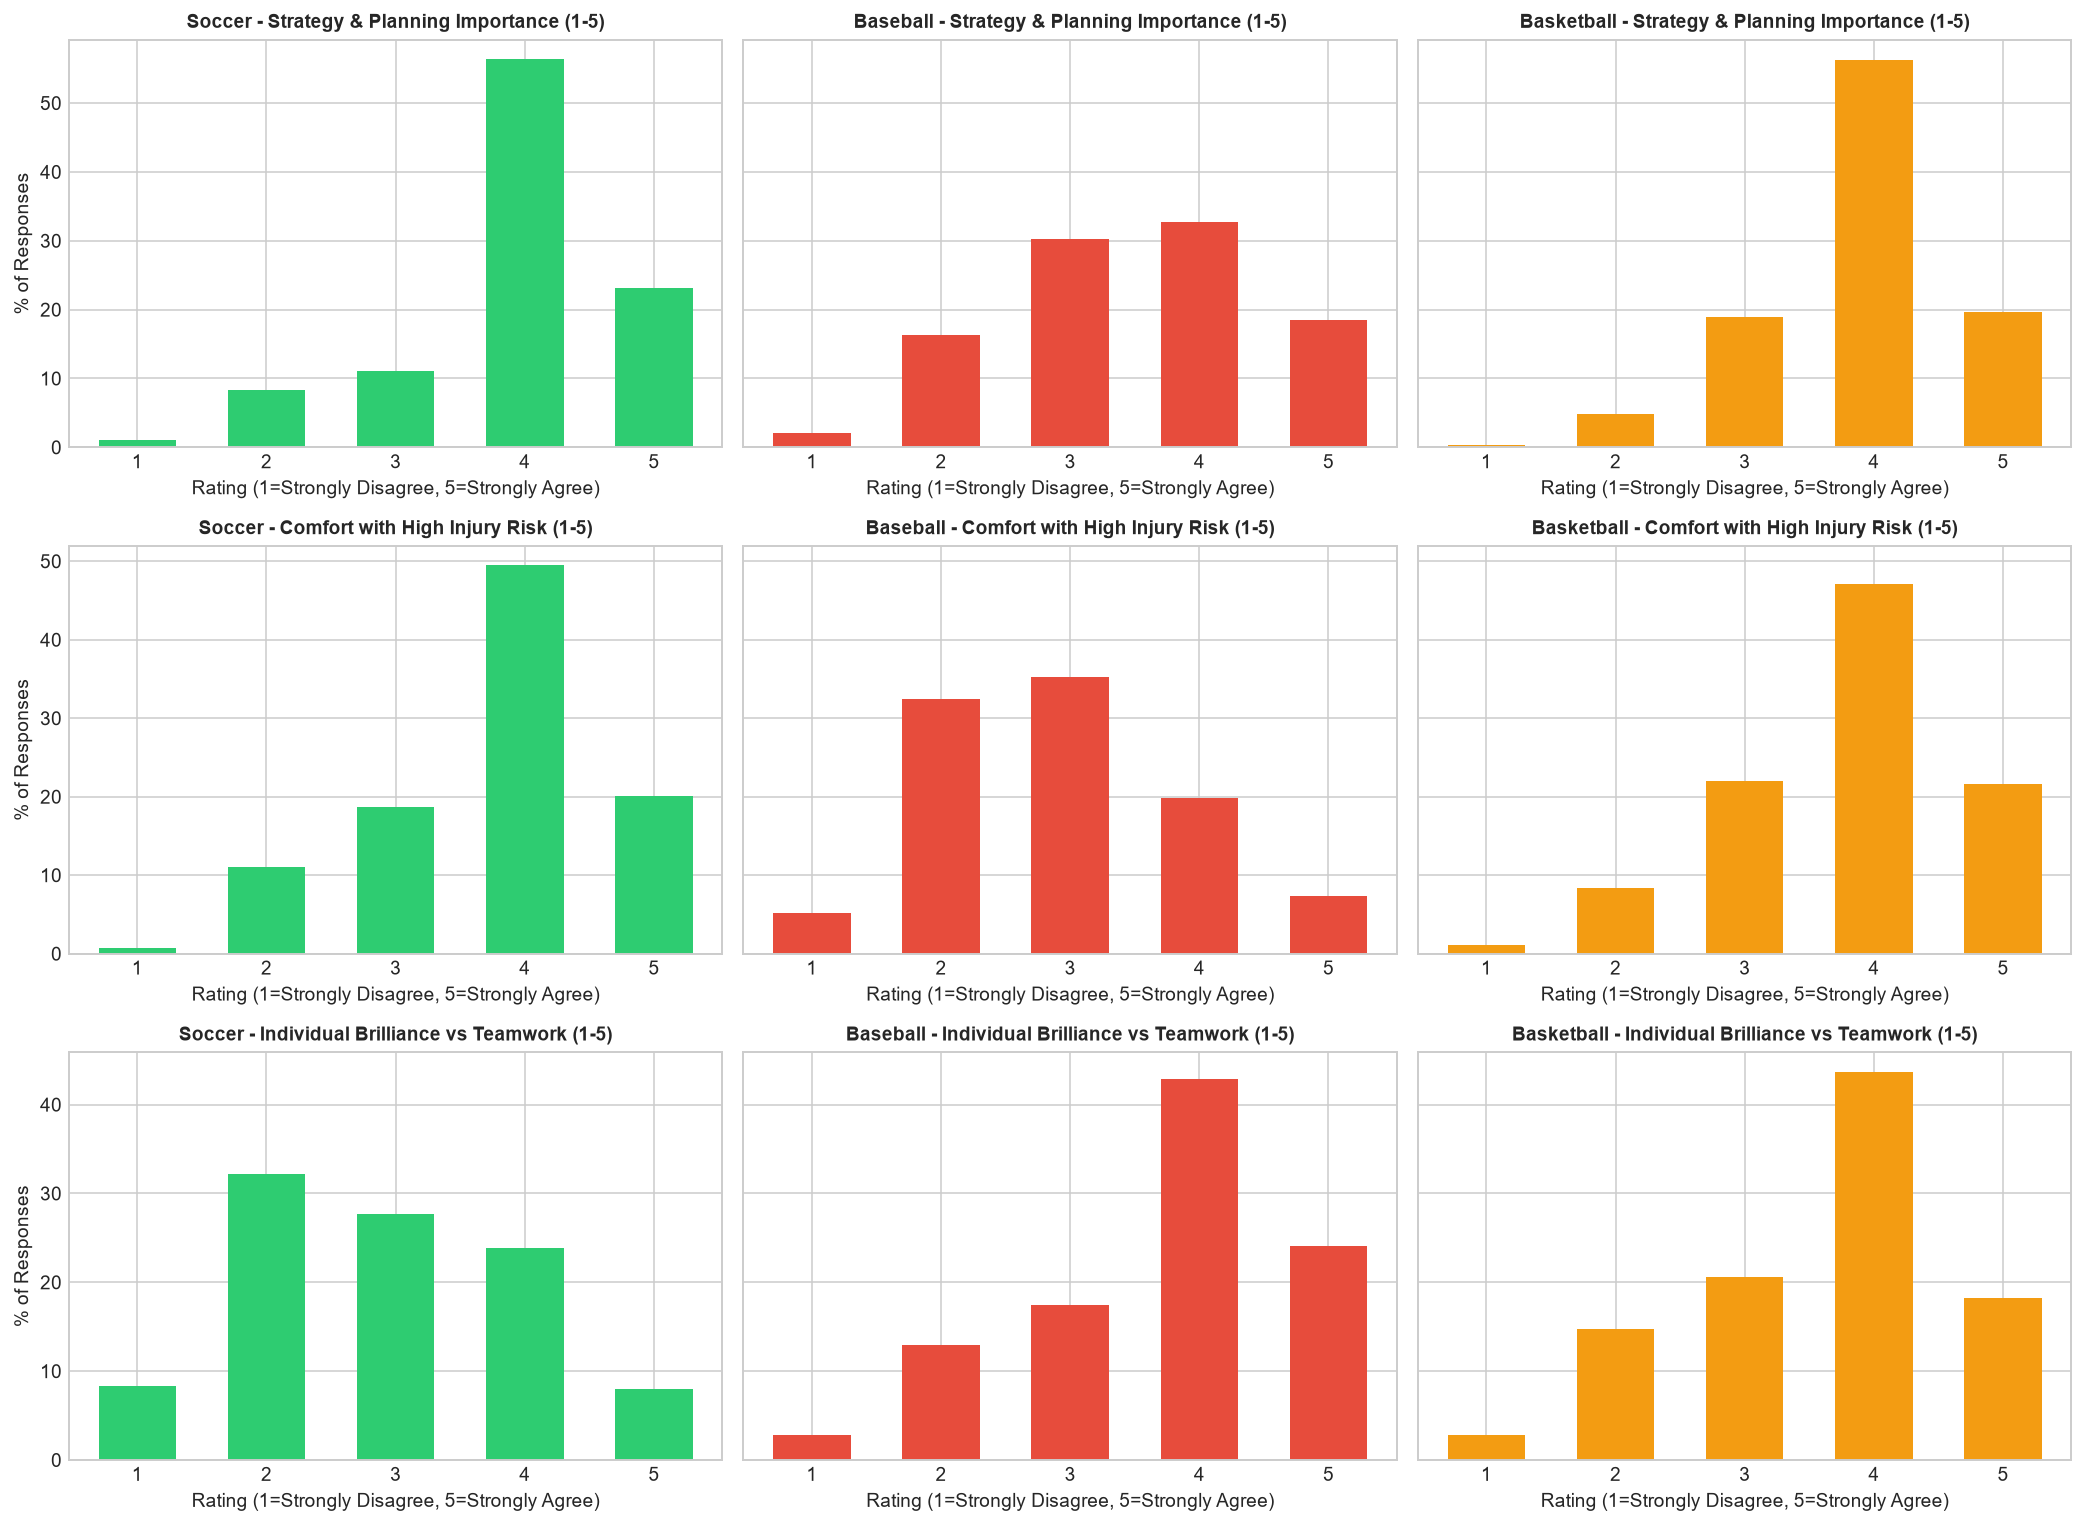

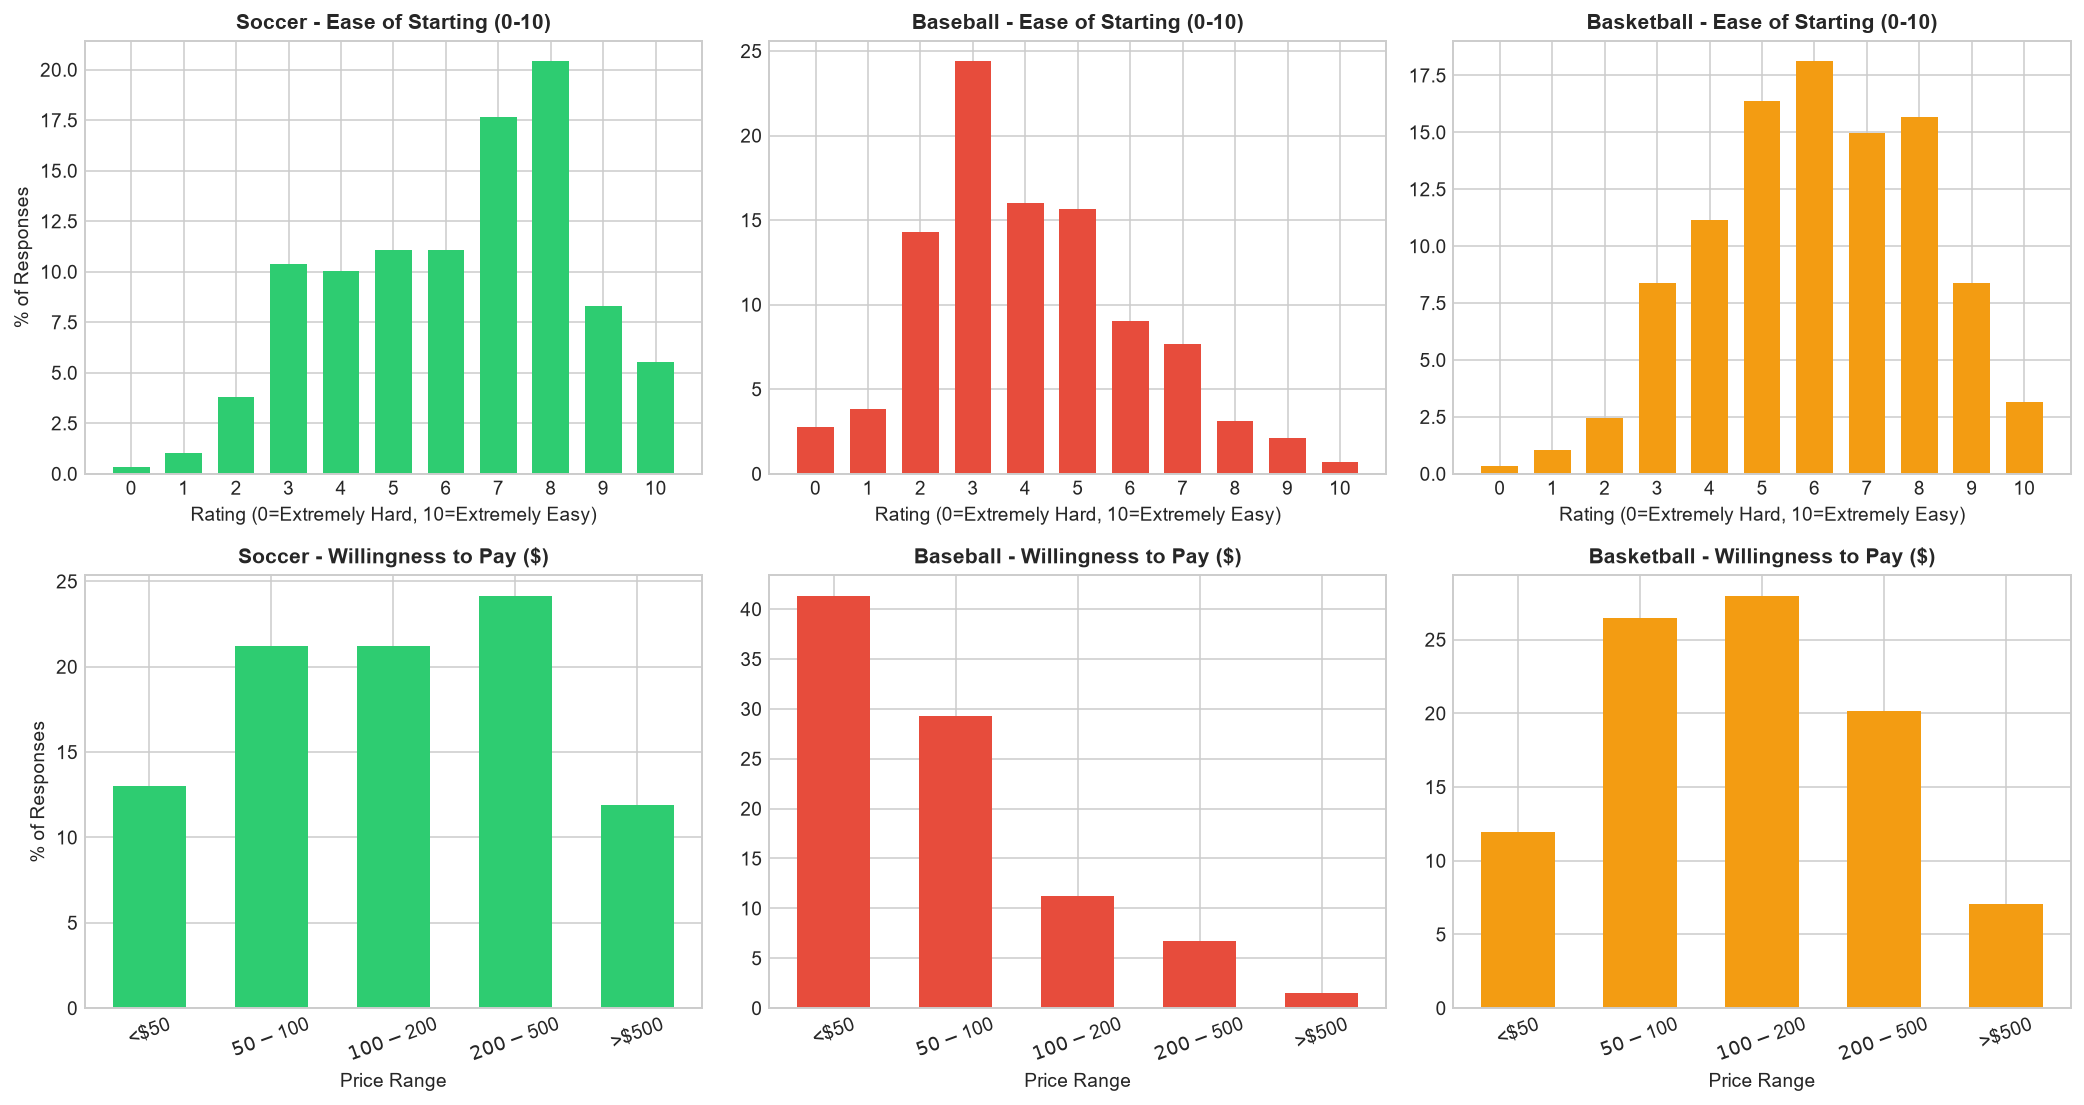

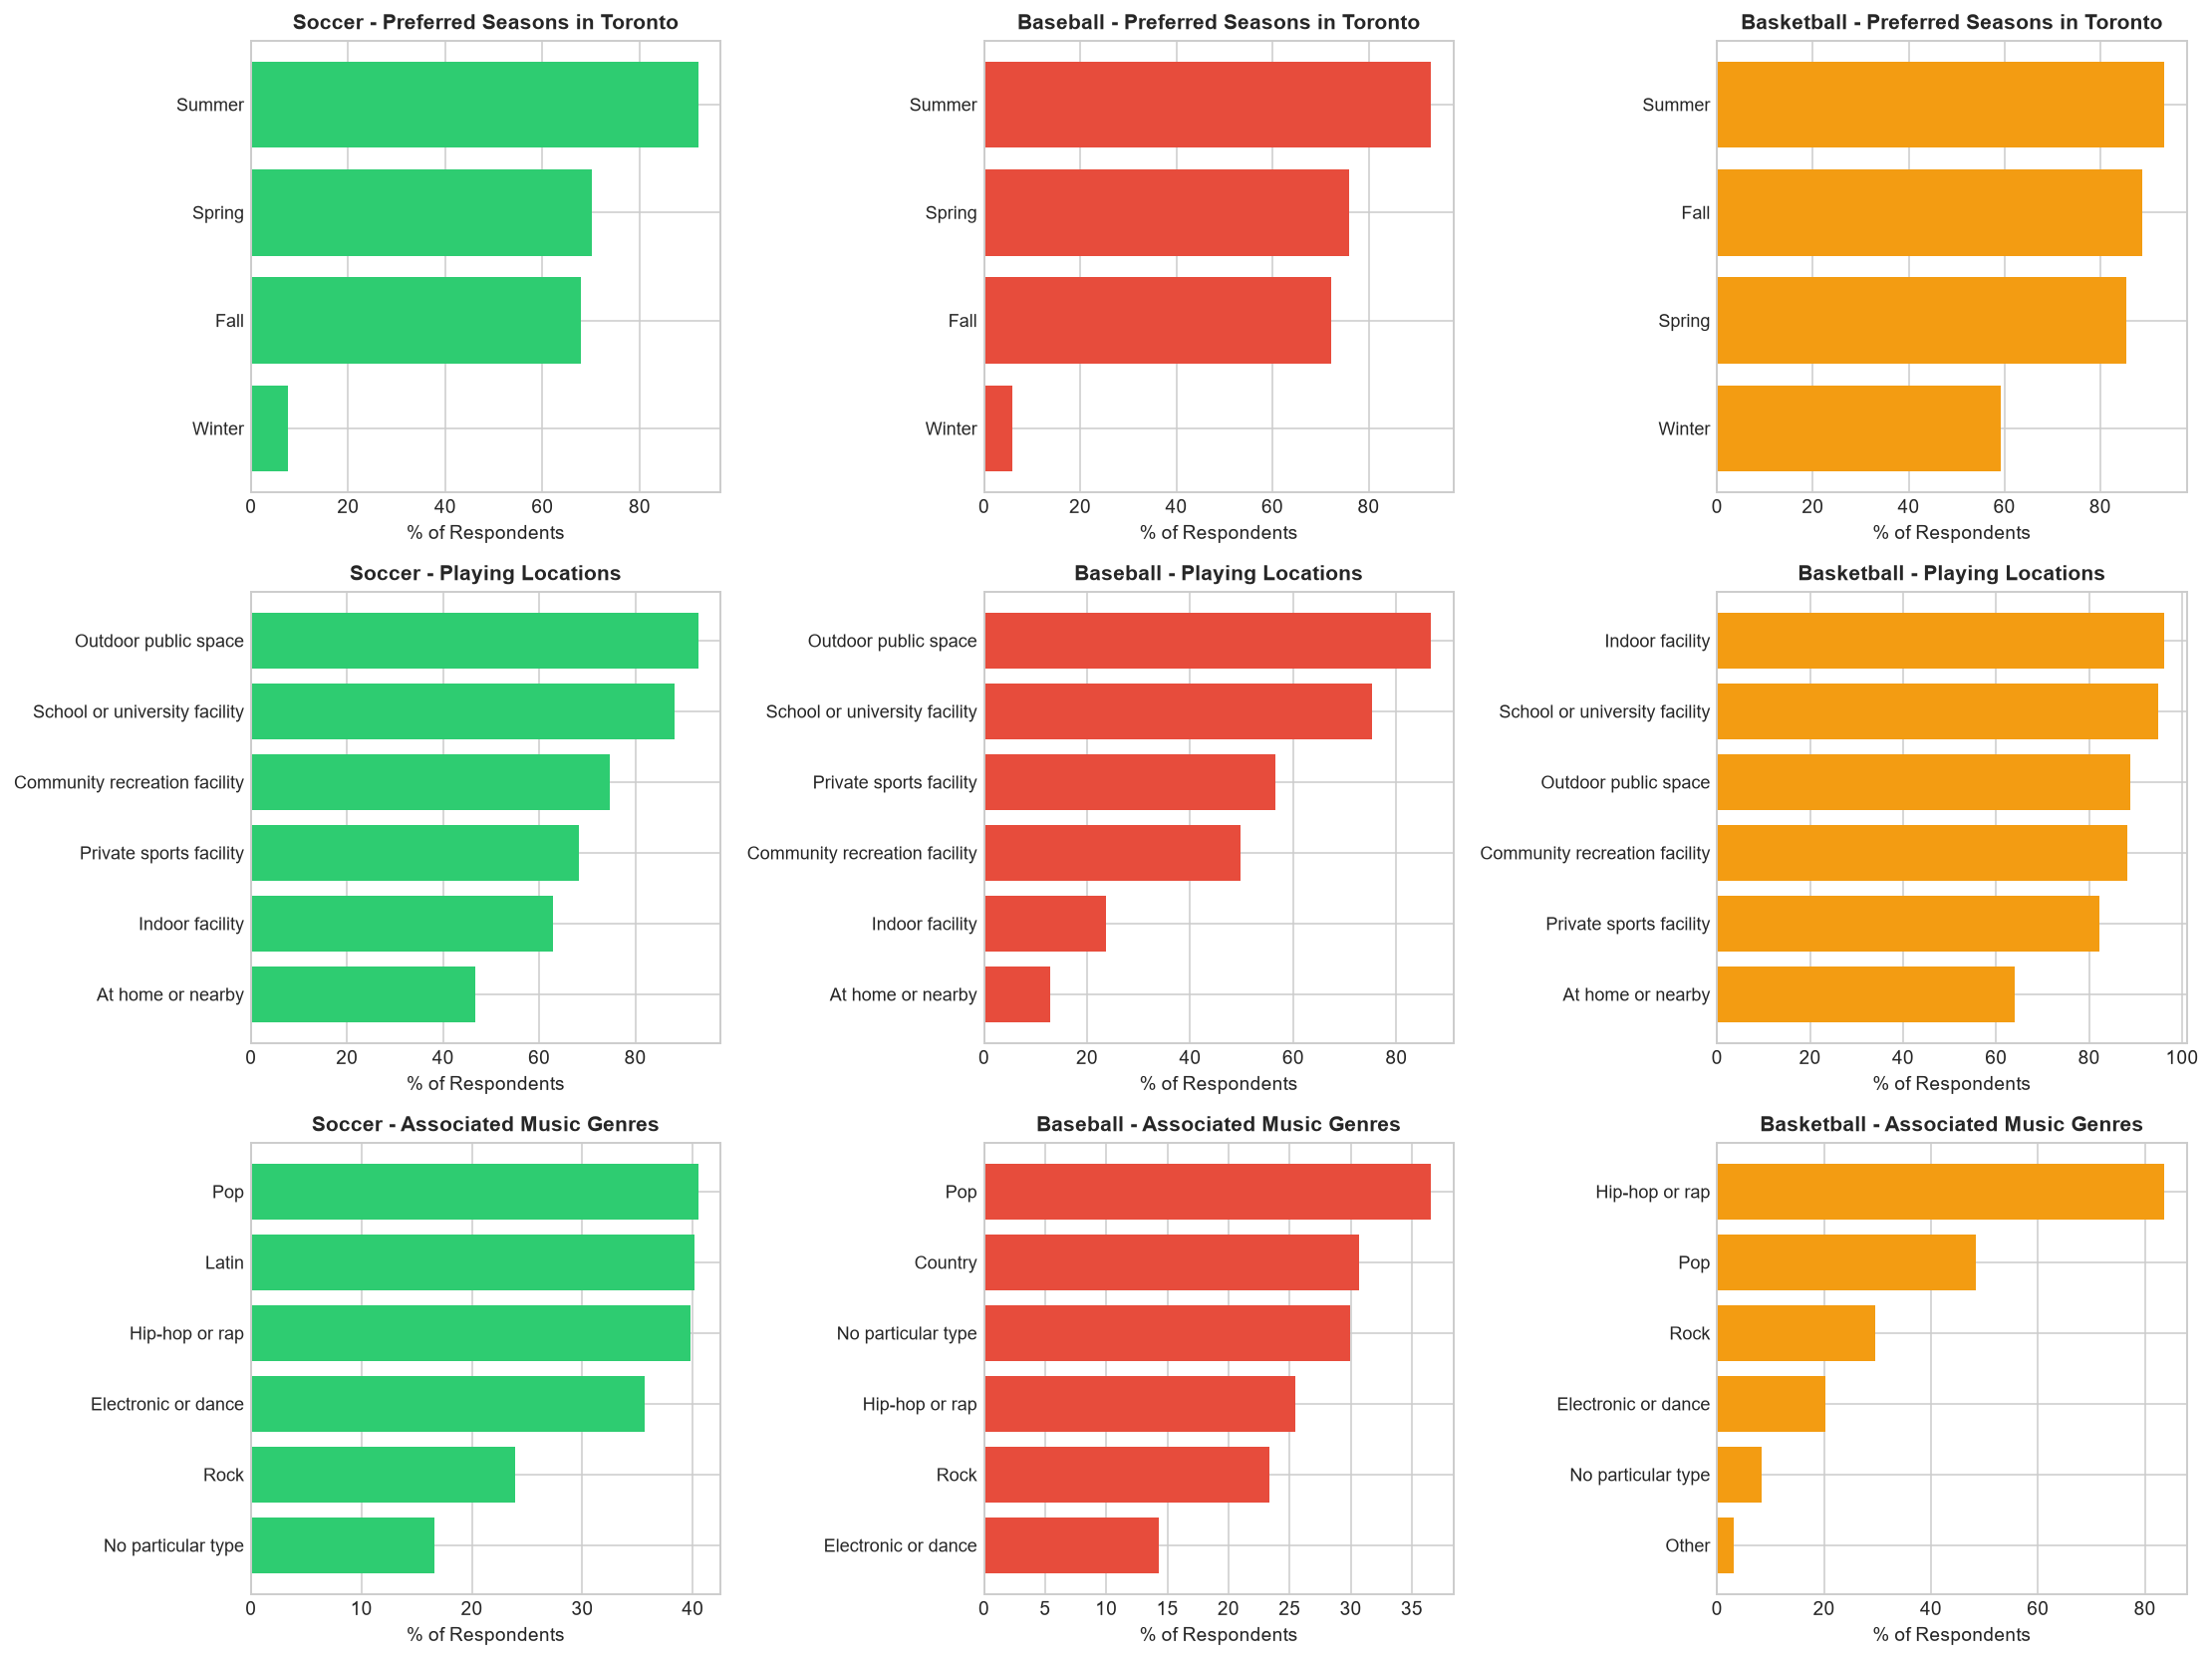

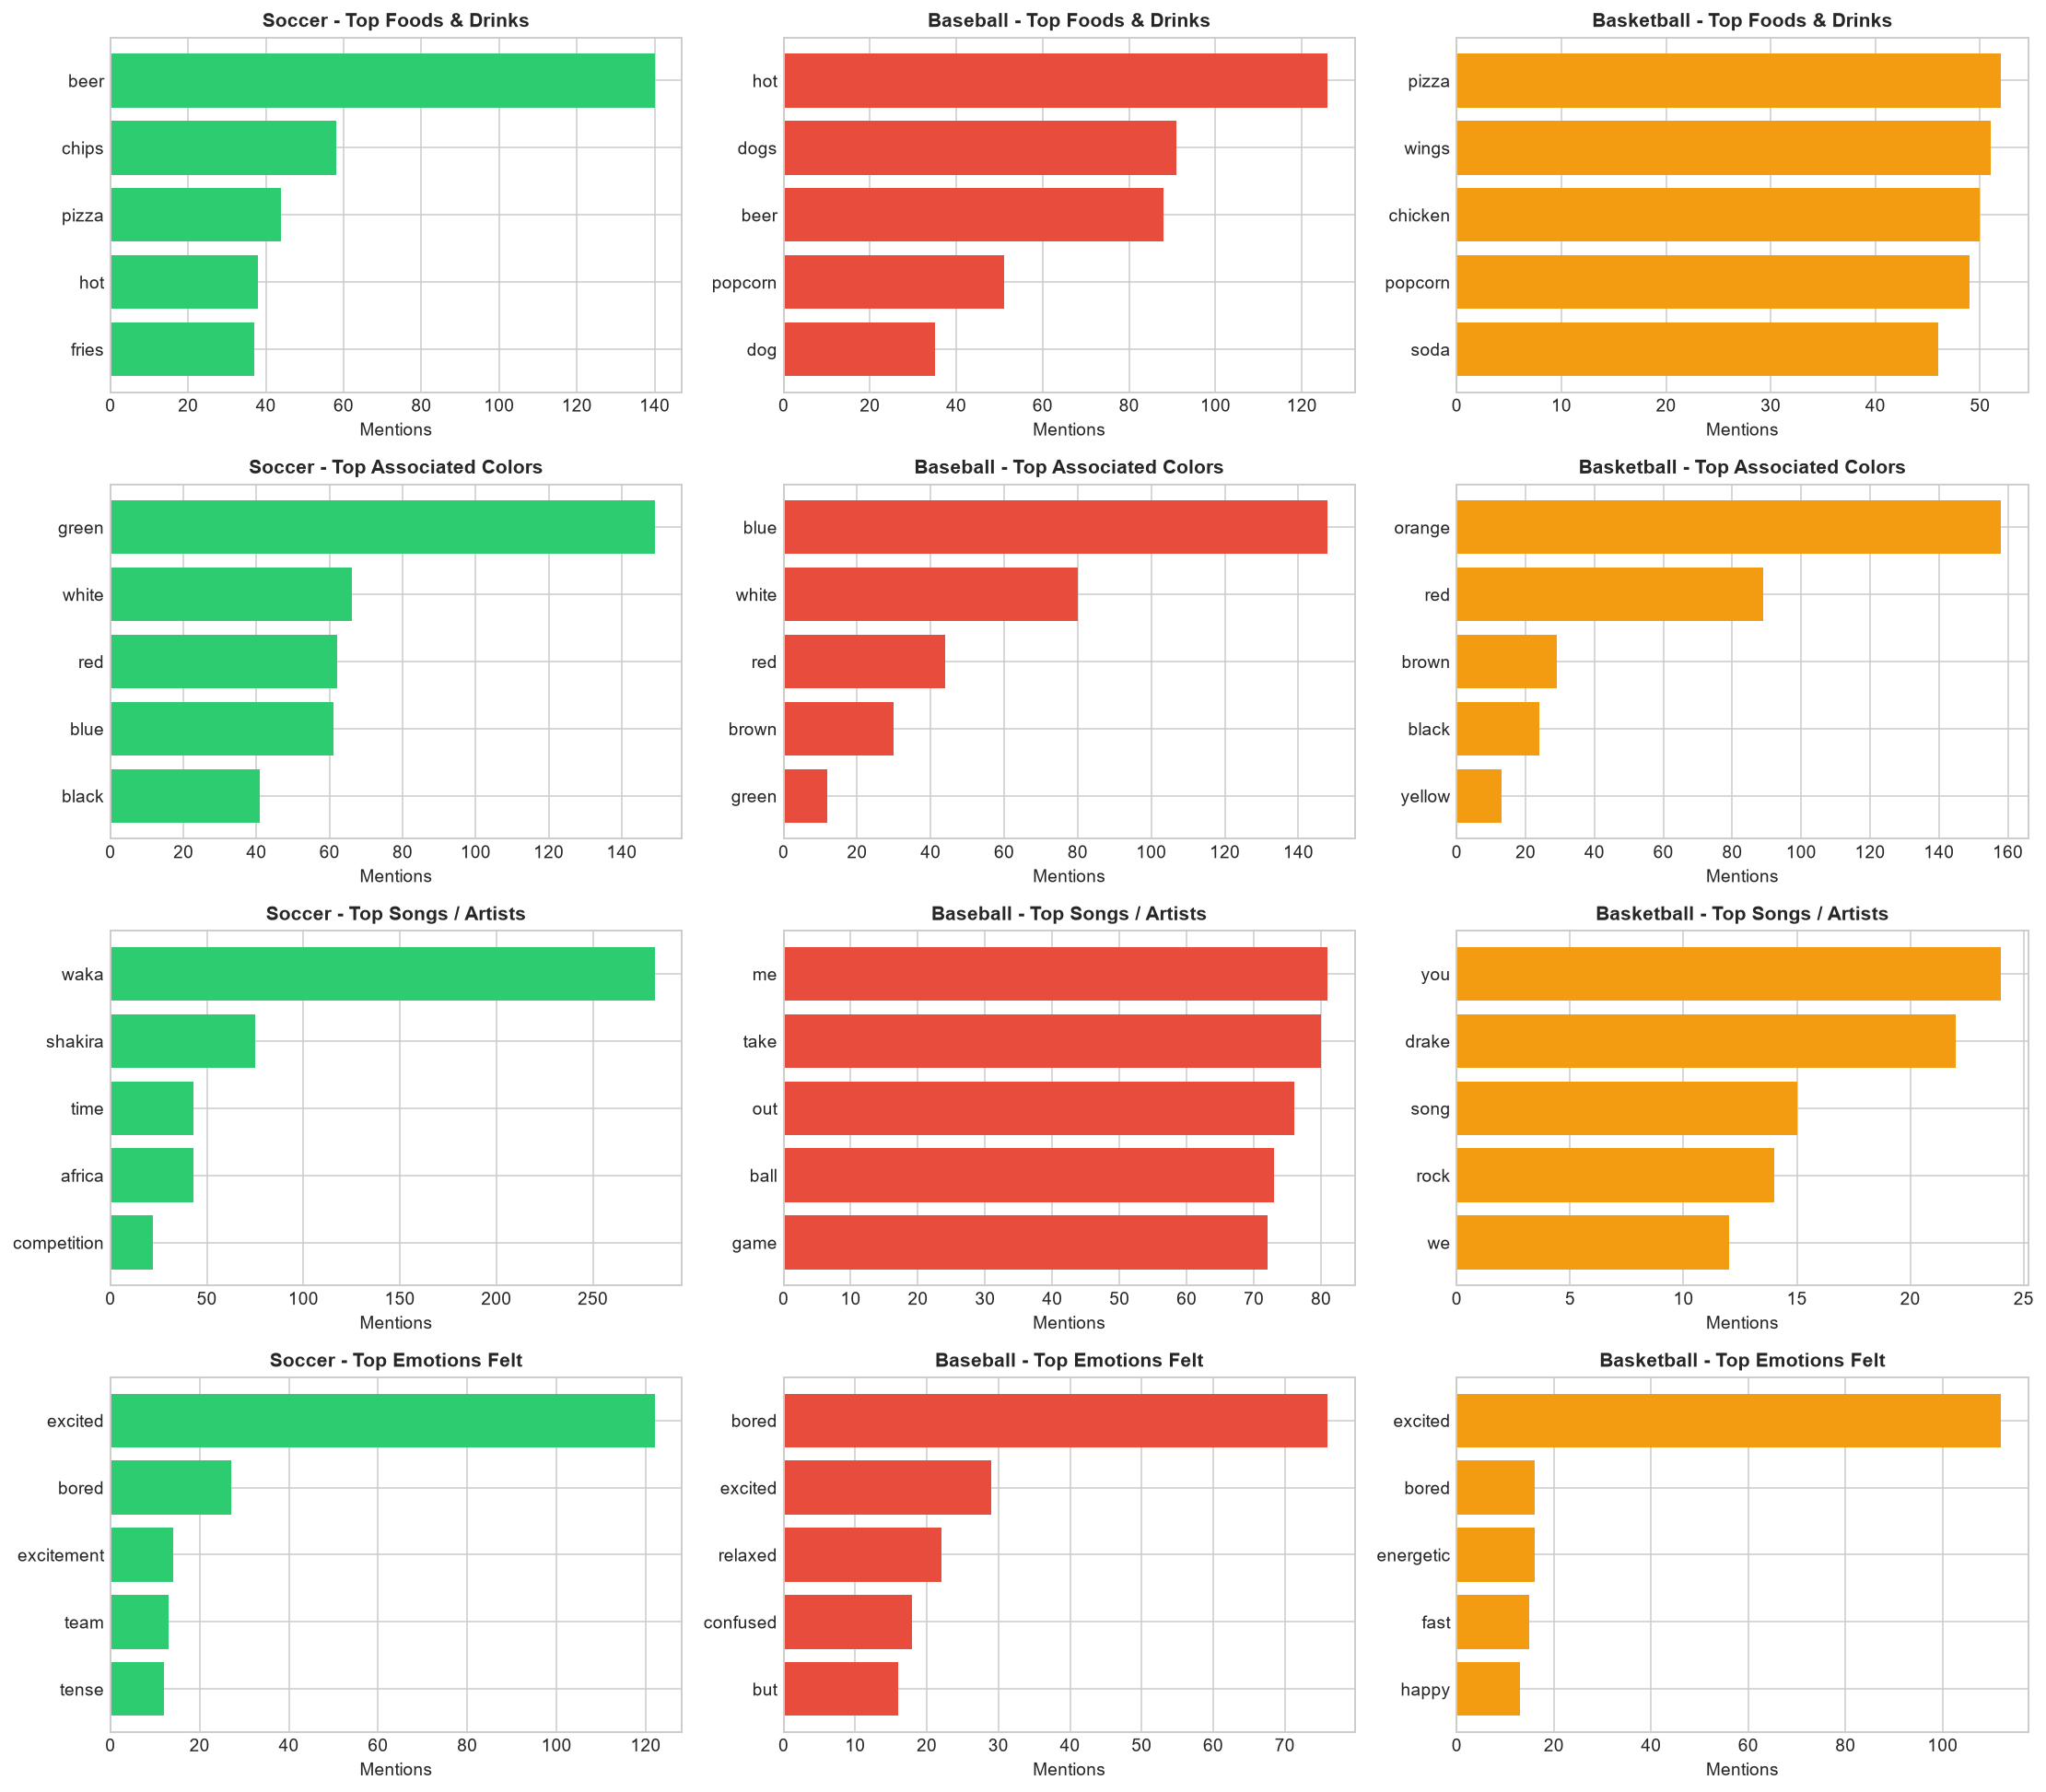

In [2]:
# =====================================================================
# PART 1: Independent 1x3 Horizontal Side-by-Side Subplots
# =====================================================================

# 1. Likert Ratings (Strategy, Injury, Brilliance) - 1x3 per row
fig1, axes1 = plt.subplots(3, 3, figsize=(15, 11), sharey="row")
likert_info = [
    ("strategy_importance_num", "Strategy & Planning Importance (1-5)"),
    ("injury_risk_comfort_num", "Comfort with High Injury Risk (1-5)"),
    ("individual_brilliance_num", "Individual Brilliance vs Teamwork (1-5)")
]
for row_idx, (col, title) in enumerate(likert_info):
    for col_idx, sport in enumerate(sports):
        ax = axes1[row_idx, col_idx]
        sub = eda_df[eda_df[label_col] == sport][col].dropna()
        counts = sub.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
        pcts = counts / len(sub) * 100
        ax.bar([1, 2, 3, 4, 5], pcts.values, color=sport_colors[sport], width=0.6)
        ax.set_title(f"{sport} - {title}", fontsize=10, fontweight="bold")
        ax.set_xticks([1, 2, 3, 4, 5])
        ax.set_xlabel("Rating (1=Strongly Disagree, 5=Strongly Agree)")
        if col_idx == 0:
            ax.set_ylabel("% of Responses")
plt.tight_layout()
plt.show()

# 2. Ease of Starting & Ticket Price - 1x3 per row
fig2, axes2 = plt.subplots(2, 3, figsize=(15, 8))
for col_idx, sport in enumerate(sports):
    ax = axes2[0, col_idx]
    sub = eda_df[eda_df[label_col] == sport]["difficulty_rating"].dropna()
    counts = sub.value_counts().reindex(range(11), fill_value=0)
    pcts = counts / len(sub) * 100
    ax.bar(range(11), pcts.values, color=sport_colors[sport], width=0.7)
    ax.set_title(f"{sport} - Ease of Starting (0-10)", fontsize=11, fontweight="bold")
    ax.set_xticks(range(11))
    ax.set_xlabel("Rating (0=Extremely Hard, 10=Extremely Easy)")
    if col_idx == 0:
        ax.set_ylabel("% of Responses")

bins = [0, 50, 100, 200, 500, 10000]
bin_labels = ["<$50", "$50-$100", "$100-$200", "$200-$500", ">$500"]
for col_idx, sport in enumerate(sports):
    ax = axes2[1, col_idx]
    sub = eda_df[eda_df[label_col] == sport]["price_clean"].dropna()
    binned = pd.cut(sub, bins=bins, labels=bin_labels, right=True)
    counts = binned.value_counts()[bin_labels]
    pcts = counts / len(sub) * 100
    ax.bar(bin_labels, pcts.values, color=sport_colors[sport], width=0.6)
    ax.set_title(f"{sport} - Willingness to Pay ($)", fontsize=11, fontweight="bold")
    ax.tick_params(axis="x", rotation=20)
    ax.set_xlabel("Price Range")
    if col_idx == 0:
        ax.set_ylabel("% of Responses")
plt.tight_layout()
plt.show()

# 3. Multi-Select (Season, Location, Music) - 1x3 per row
fig3, axes3 = plt.subplots(3, 3, figsize=(16, 12))
multi_info = [
    ("play_season", "Preferred Seasons in Toronto"),
    ("play_location", "Playing Locations"),
    ("associated_music", "Associated Music Genres")
]
for row_idx, (col, title) in enumerate(multi_info):
    for col_idx, sport in enumerate(sports):
        ax = axes3[row_idx, col_idx]
        sub = eda_df[eda_df[label_col] == sport][col].dropna()
        items = [x.strip() for val in sub for x in str(val).split(",") if x.strip()]
        top_cats = Counter(items).most_common(6)
        if top_cats:
            cat_names, cat_counts = zip(*top_cats)
            cat_pcts = [cnt / len(sub) * 100 for cnt in cat_counts]
            y_pos = range(len(cat_names))
            ax.barh(y_pos, cat_pcts, color=sport_colors[sport], align="center")
            ax.set_yticks(y_pos)
            ax.set_yticklabels(cat_names, fontsize=9)
            ax.invert_yaxis()
            ax.set_xlabel("% of Respondents")
        ax.set_title(f"{sport} - {title}", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

# 4. Free-Text Keywords (Foods, Colors, Songs, Emotions) - 1x3 per row
fig4, axes4 = plt.subplots(4, 3, figsize=(16, 14))
text_info = [
    ("associated_foods_drinks", "Top Foods & Drinks"),
    ("associated_color", "Top Associated Colors"),
    ("associated_song", "Top Songs / Artists"),
    ("emotional_response", "Top Emotions Felt")
]
stop_words = {
    "and", "or", "the", "a", "an", "in", "on", "with", "to", "of", "for",
    "is", "it", "sport", "watching", "feel", "when", "i", "na", "n/a", "none", "no",
    "this", "that", "at", "by", "from"
}
for row_idx, (col, title) in enumerate(text_info):
    for col_idx, sport in enumerate(sports):
        ax = axes4[row_idx, col_idx]
        sub = eda_df[eda_df[label_col] == sport][col].dropna()
        words = [w for text in sub for w in re.findall(r"\b[a-zA-Z]{2,}\b", str(text).lower()) if w not in stop_words]
        top_w = Counter(words).most_common(5)
        if top_w:
            w_labels, w_counts = zip(*top_w)
            y_pos = range(len(w_labels))
            ax.barh(y_pos, w_counts, color=sport_colors[sport], align="center")
            ax.set_yticks(y_pos)
            ax.set_yticklabels(w_labels, fontsize=10)
            ax.invert_yaxis()
            ax.set_xlabel("Mentions")
        ax.set_title(f"{sport} - {title}", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()


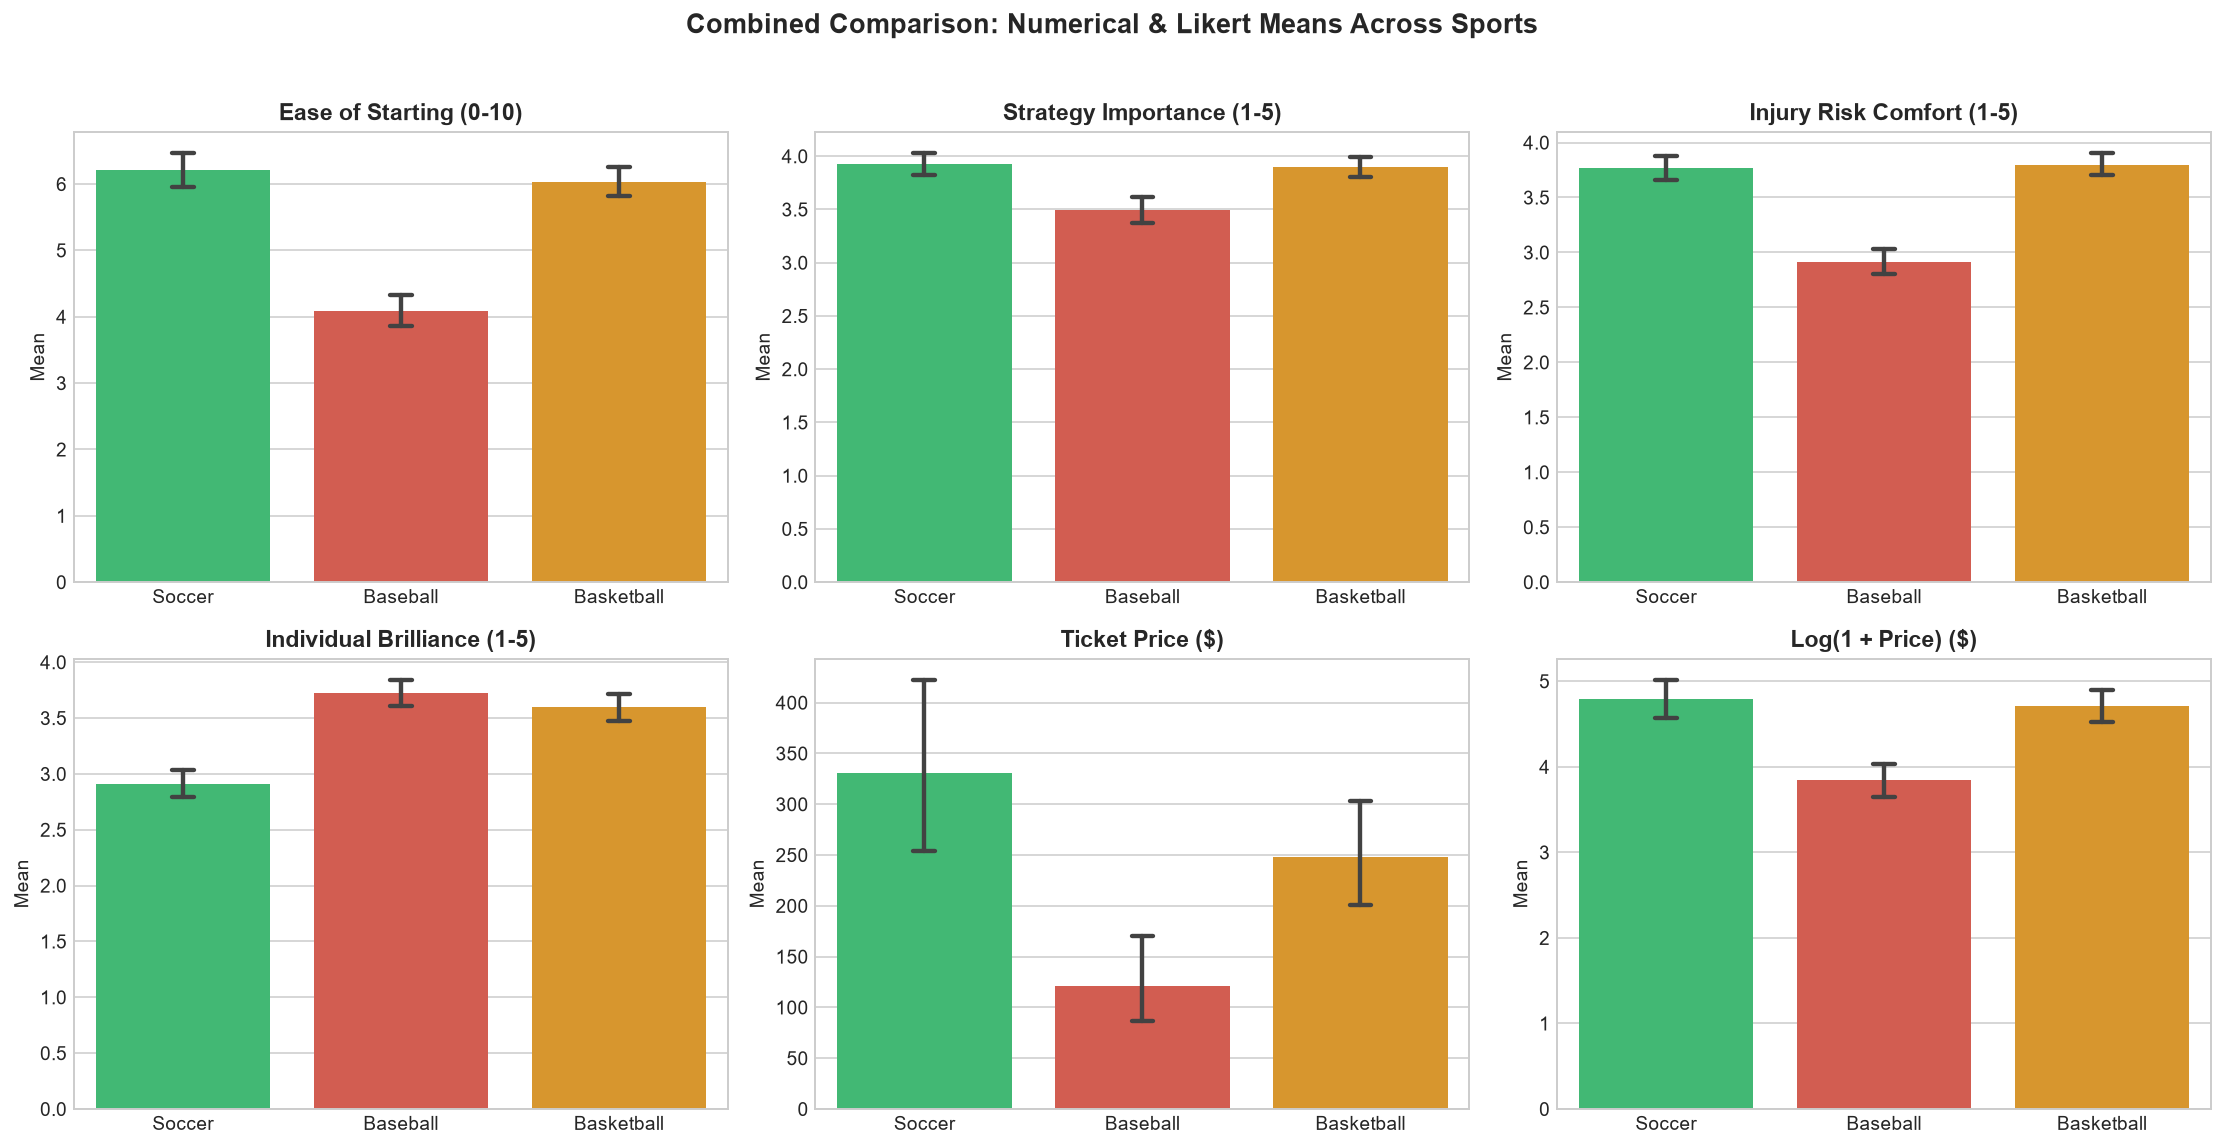

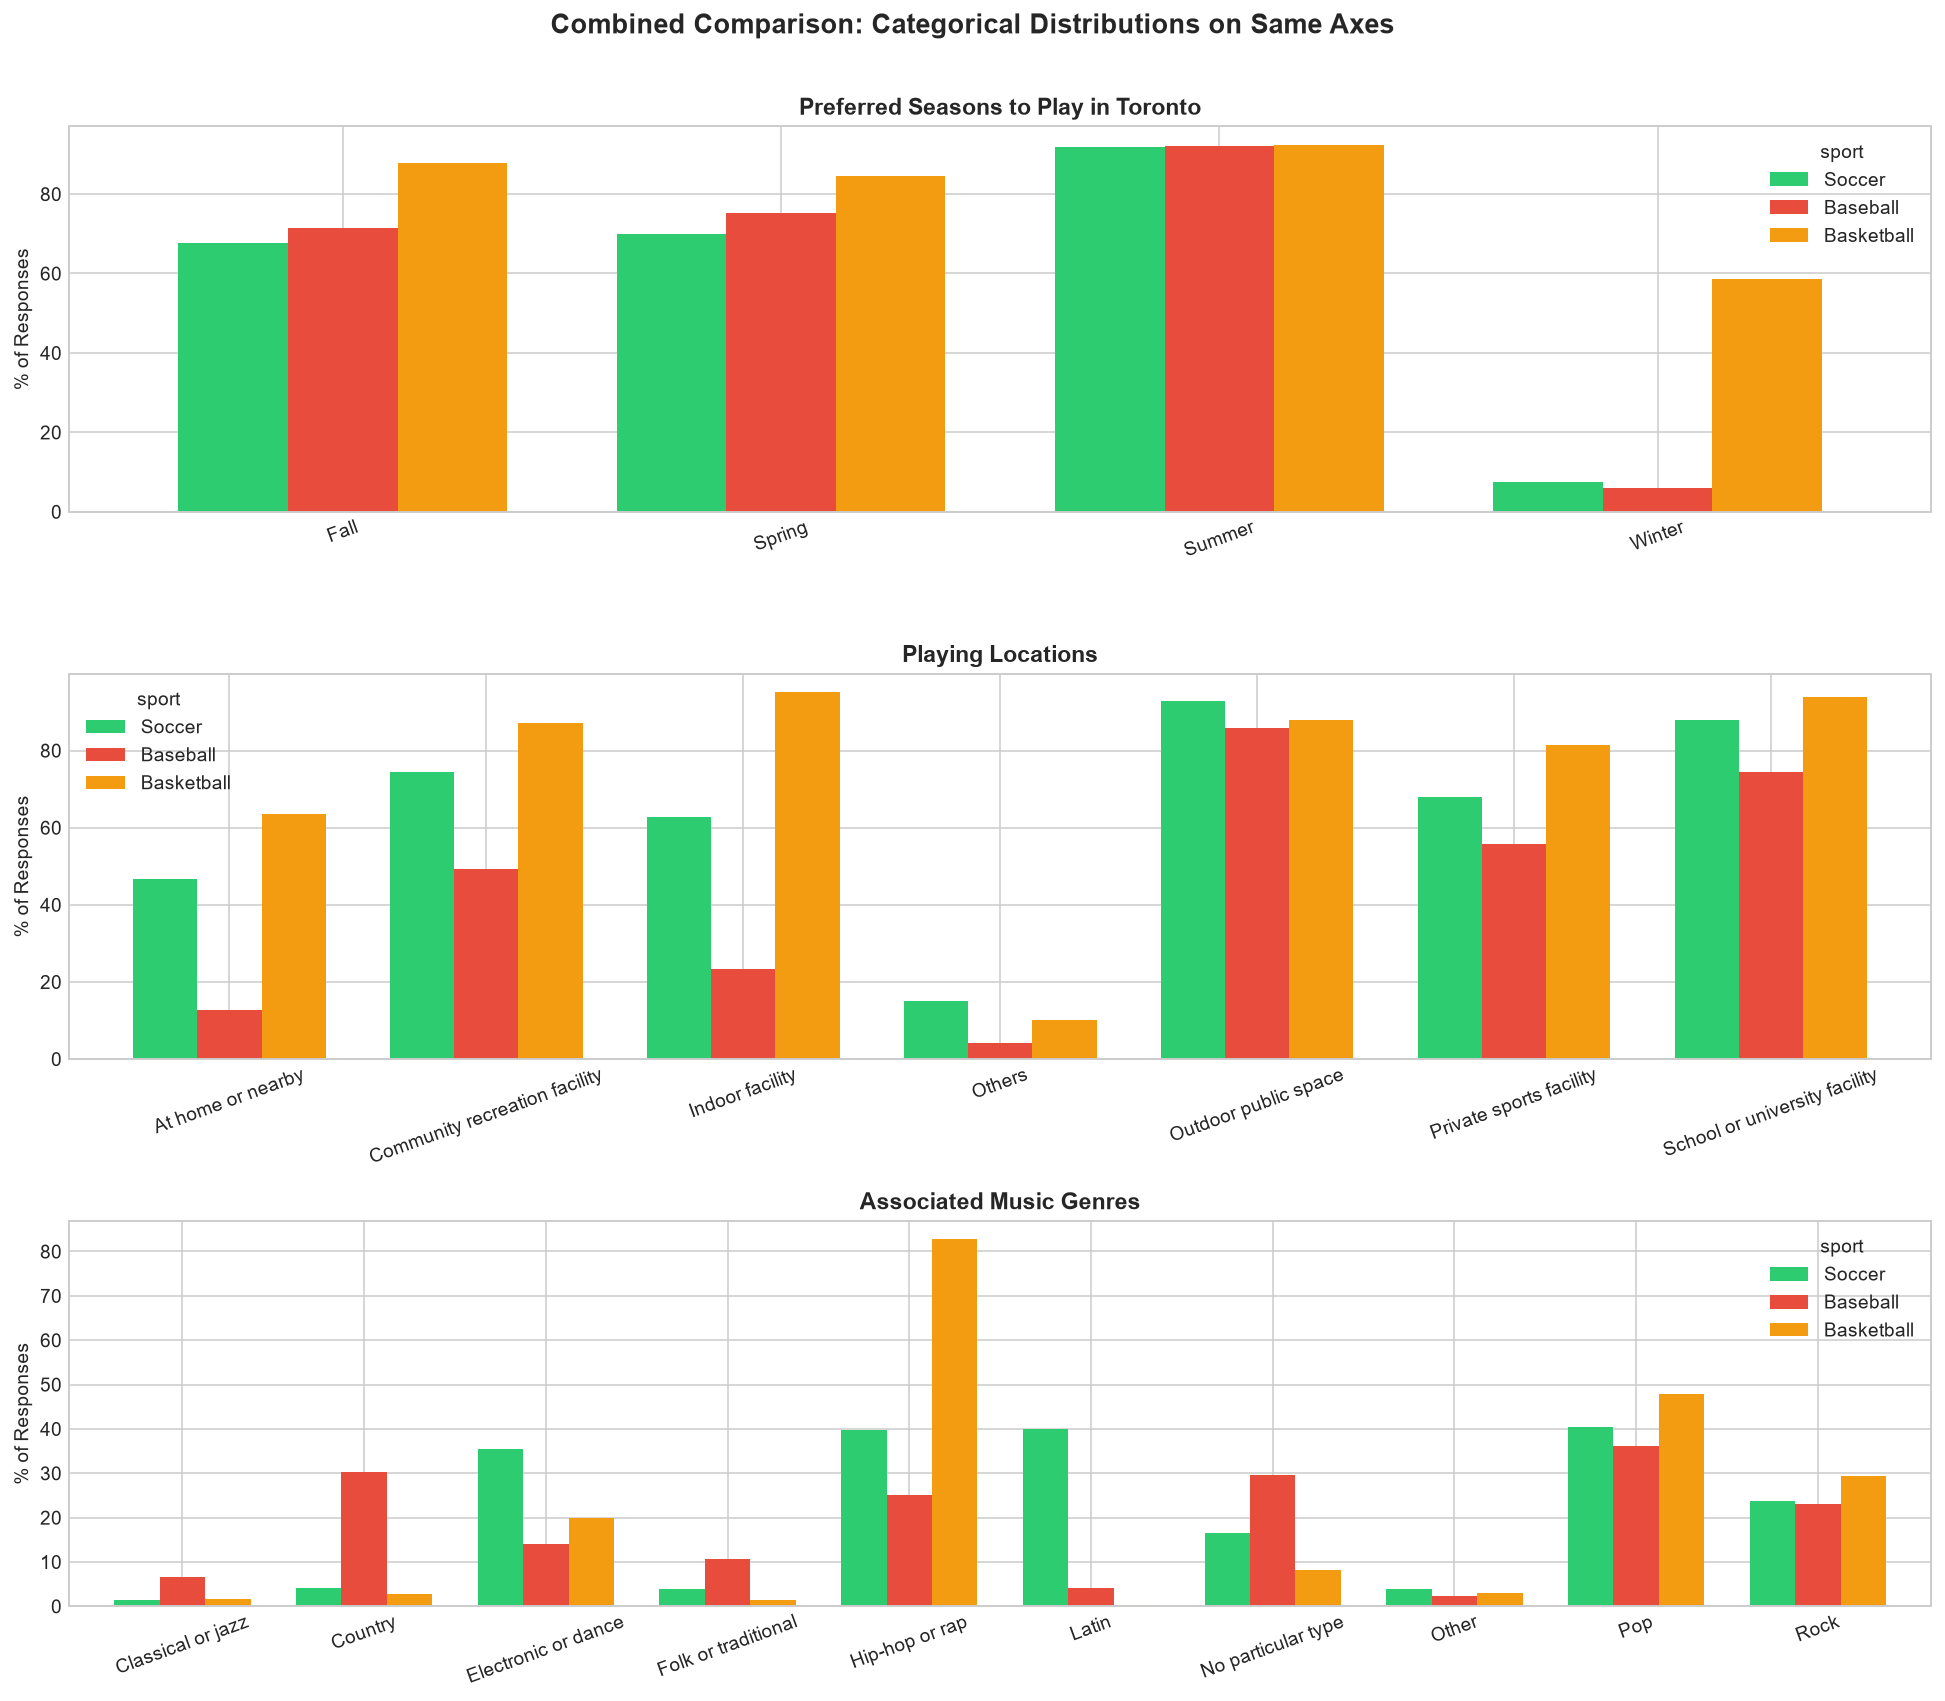

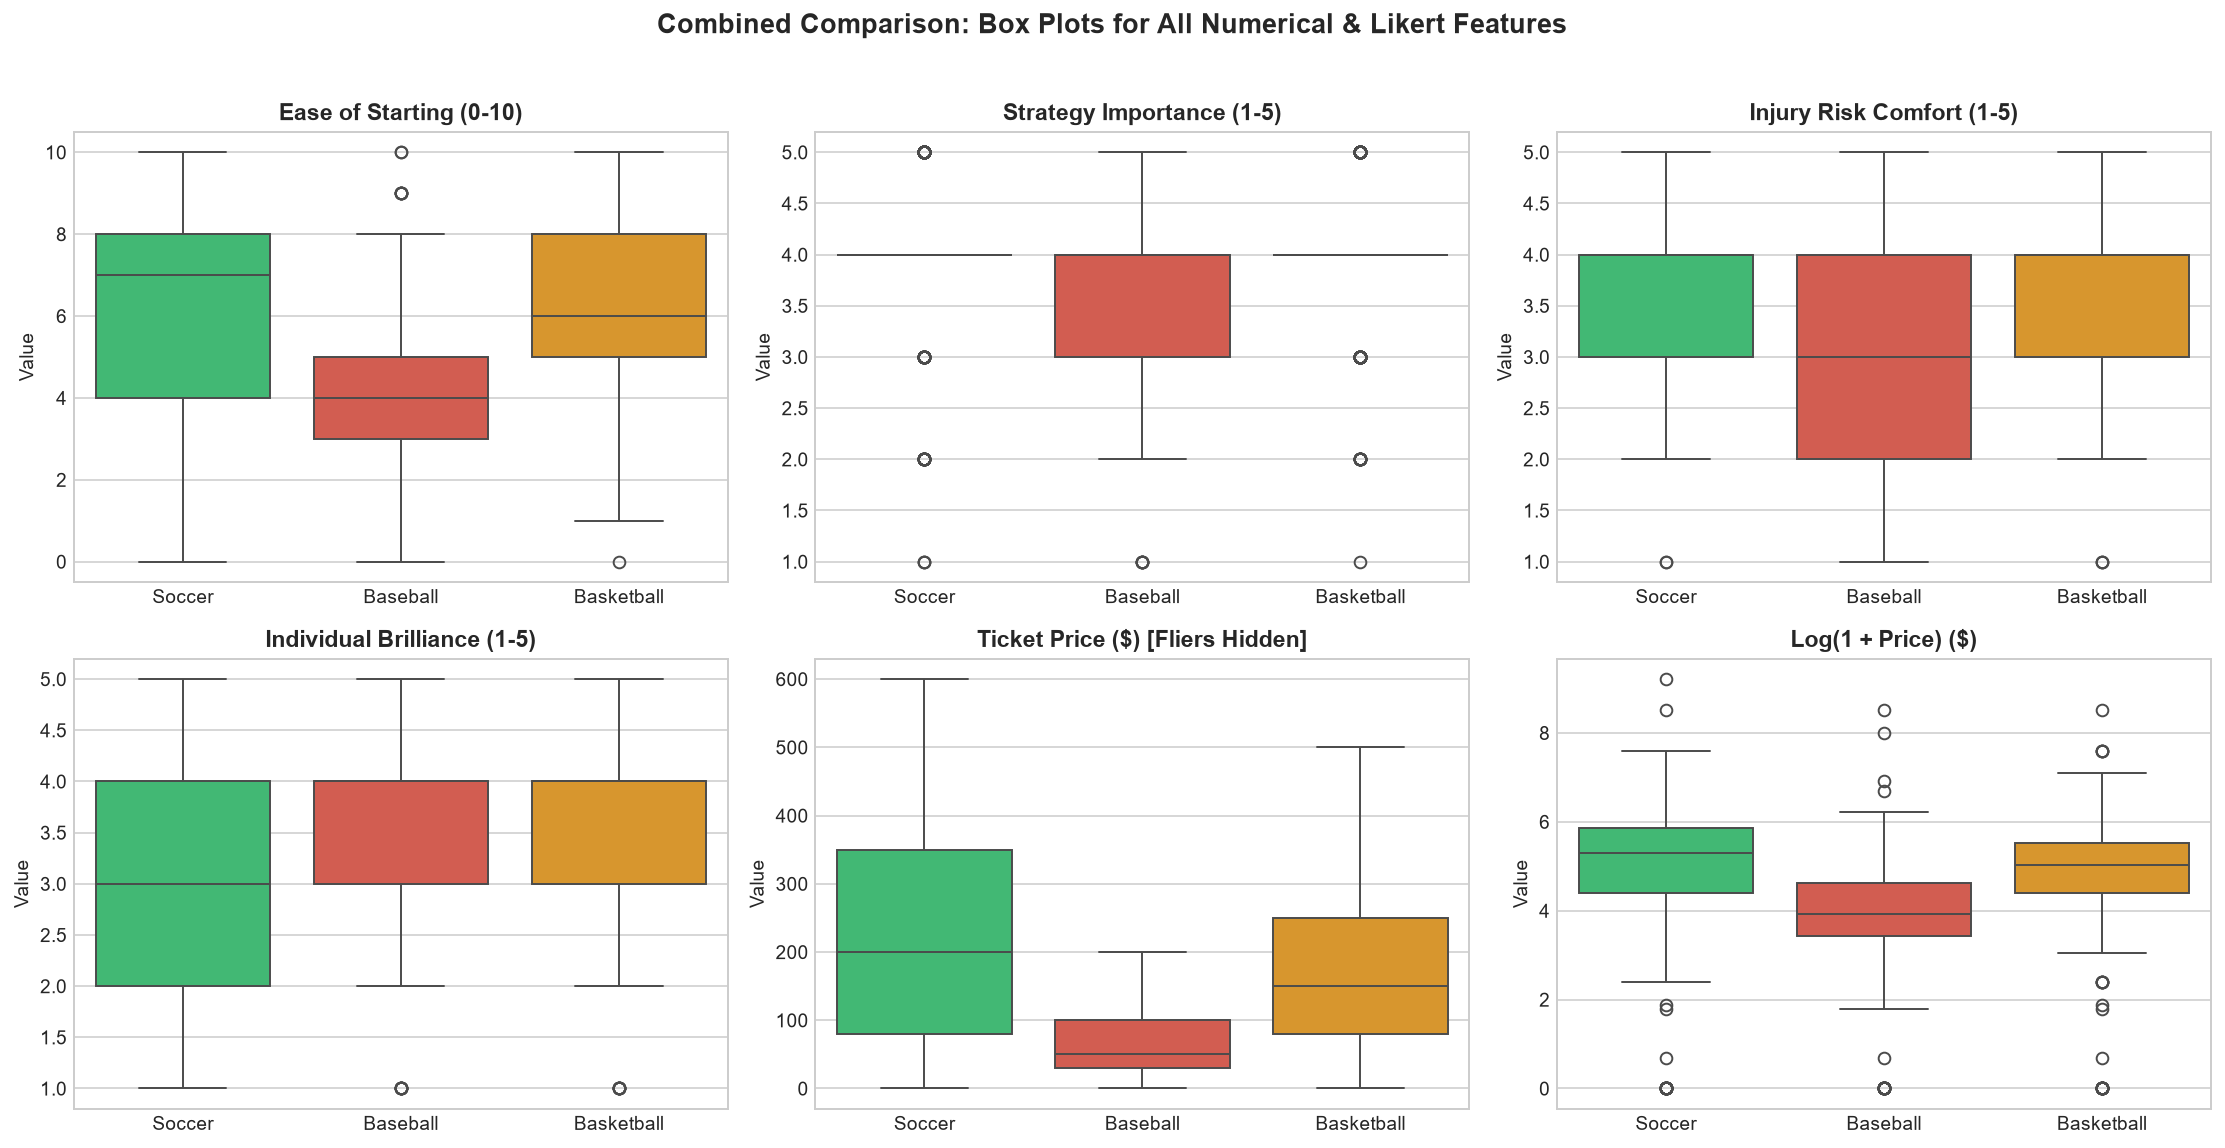

In [3]:
# =====================================================================
# PART 2: Combined Grouped Comparisons (All 3 Sports on Same Axes)
# =====================================================================

# 1. Combined Mean Bar Plots for Numerical & Likert Features
fig5, axes5 = plt.subplots(2, 3, figsize=(16, 8))
num_cols = [
    ("difficulty_rating", "Ease of Starting (0-10)"),
    ("strategy_importance_num", "Strategy Importance (1-5)"),
    ("injury_risk_comfort_num", "Injury Risk Comfort (1-5)"),
    ("individual_brilliance_num", "Individual Brilliance (1-5)"),
    ("price_clean", "Ticket Price ($)"),
    ("log_price", "Log(1 + Price) ($)")
]
for idx, (col, title) in enumerate(num_cols):
    ax = axes5[idx // 3, idx % 3]
    sns.barplot(data=eda_df, x=label_col, y=col, ax=ax, palette=sport_colors, capsize=0.1, estimator=np.nanmean)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Mean")
plt.suptitle("Combined Comparison: Numerical & Likert Means Across Sports", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# 2. Combined Grouped Bar Plots for Multi-Select Categorical Features
fig6, axes6 = plt.subplots(3, 1, figsize=(14, 12))
multi_cols = [
    ("play_season", "Preferred Seasons to Play in Toronto"),
    ("play_location", "Playing Locations"),
    ("associated_music", "Associated Music Genres")
]
for idx, (col, title) in enumerate(multi_cols):
    expanded = []
    for _, row in eda_df.dropna(subset=[col, label_col]).iterrows():
        sport = row[label_col]
        items = [x.strip() for x in str(row[col]).split(",") if x.strip()]
        for item in items:
            expanded.append({"sport": sport, "category": item})
    df_cat = pd.DataFrame(expanded)
    sport_counts = eda_df[label_col].value_counts()
    cat_pct = (df_cat.groupby(["category", "sport"]).size().unstack(fill_value=0)).div(sport_counts, axis=1) * 100
    avail = [s for s in ["Soccer", "Baseball", "Basketball"] if s in cat_pct.columns]
    cat_pct[avail].plot(kind="bar", ax=axes6[idx], color=["#2ecc71", "#e74c3c", "#f39c12"], width=0.75)
    axes6[idx].set_title(title, fontweight="bold")
    axes6[idx].set_ylabel("% of Responses")
    axes6[idx].set_xlabel("")
    axes6[idx].tick_params(axis="x", rotation=20)
plt.suptitle("Combined Comparison: Categorical Distributions on Same Axes", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# 3. Combined Box Plots for All Numerical & Likert Features
fig7, axes7 = plt.subplots(2, 3, figsize=(16, 8))
box_cols = [
    ("difficulty_rating", "Ease of Starting (0-10)"),
    ("strategy_importance_num", "Strategy Importance (1-5)"),
    ("injury_risk_comfort_num", "Injury Risk Comfort (1-5)"),
    ("individual_brilliance_num", "Individual Brilliance (1-5)"),
    ("price_clean", "Ticket Price ($) [Fliers Hidden]"),
    ("log_price", "Log(1 + Price) ($)")
]
for idx, (col, title) in enumerate(box_cols):
    ax = axes7[idx // 3, idx % 3]
    show_fliers = False if col == "price_clean" else True
    sns.boxplot(data=eda_df, x=label_col, y=col, ax=ax, palette=sport_colors, showfliers=show_fliers)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Value")
plt.suptitle("Combined Comparison: Box Plots for All Numerical & Likert Features", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()
